<a href="https://colab.research.google.com/github/Vaidehigupta05/crack_detection_severity_estimation/blob/main/Final_trained_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

# Connect your Google Drive to Colab
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Install KaggleHub to download datasets from Kaggle
!pip install -q kagglehub

import kagglehub
import os
import shutil

In [3]:
# Main project folder in Google Drive
PROJECT_PATH = "/content/drive/MyDrive/Crack_Detection_Project"

# Create folders for datasets, models and results
os.makedirs(PROJECT_PATH, exist_ok=True)
os.makedirs(PROJECT_PATH + "/datasets", exist_ok=True)
os.makedirs(PROJECT_PATH + "/models", exist_ok=True)
os.makedirs(PROJECT_PATH + "/results", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [4]:
# Download the cracked and non-cracked surface dataset
dataset1_path = kagglehub.dataset_download(
    "geadalfa/cracked-non-cracked-surface-datasets"
)

print("Dataset 1 downloaded!")
print("Location:", dataset1_path)

100%|██████████| 741M/741M [00:18<00:00, 42.1MB/s]

Extracting files...


Dataset 1 downloaded!
Location: /root/.cache/kagglehub/datasets/geadalfa/cracked-non-cracked-surface-datasets/versions/1


In [5]:
# Download the crack segmentation dataset
dataset2_path = kagglehub.dataset_download(
    "aravindnagarajan/crack-segmentation-dataset"
)

print("Dataset 2 downloaded!")
print("Location:", dataset2_path)

100%|██████████| 0.99G/0.99G [00:25<00:00, 41.9MB/s]

Extracting files...


Dataset 2 downloaded!
Location: /root/.cache/kagglehub/datasets/aravindnagarajan/crack-segmentation-dataset/versions/3


In [6]:
# Download the surface crack detection dataset
dataset3_path = kagglehub.dataset_download(
    "arunrk7/surface-crack-detection"
)

print("Dataset 3 downloaded!")
print("Location:", dataset3_path)

100%|██████████| 233M/233M [00:06<00:00, 37.1MB/s]

Extracting files...


Dataset 3 downloaded!
Location: /root/.cache/kagglehub/datasets/arunrk7/surface-crack-detection/versions/1


In [7]:
# Display the folder structure of each downloaded dataset

datasets = {
    "Dataset 1": dataset1_path,
    "Dataset 2": dataset2_path,
    "Dataset 3": dataset3_path
}

for name, path in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)

        # Avoid printing an excessively long folder tree
        if level > 3:
            dirs[:] = []
            continue

        indent = " " * 4 * level
        print(indent + os.path.basename(root) + "/")

        for file in files[:5]:
            print(indent + "    " + file)

        if len(files) > 5:
            print(indent + f"    ... and {len(files)-5} more files")


Dataset 1
1/
    Bangunan Retak/
        Cracked/
            7036-30.jpg
            098-101.jpg
            05730.jpg
            7083-167.jpg
            06497.jpg
            ... and 28479 more files
        Non Cracked/
            009-170.jpg
            001-72.jpg
            11360.jpg
            7018-107.jpg
            096-144.jpg
            ... and 67603 more files

Dataset 2
3/
    train/
        masks/
            Rissbilder_for_Florian_9S6A3085_557_1371_2519_2594.jpg
            CRACK500_20160328_154352_1_1.jpg
            Rissbilder_for_Florian_9S6A3092_0_0_5760_3840.jpg
            Rissbilder_for_Florian_9S6A2849_185_1761_2918_3091.jpg
            noncrack_noncrack_concrete_wall_45_15.jpg.jpg
            ... and 9598 more files
        images/
            Rissbilder_for_Florian_9S6A3085_557_1371_2519_2594.jpg
            CRACK500_20160328_154352_1_1.jpg
            Rissbilder_for_Florian_9S6A3092_0_0_5760_3840.jpg
            Rissbilder_for_Florian_9S6A2849_185_1761_2

In [8]:
# Inspect the number of images and subfolders in each dataset

from collections import Counter

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

for name, path in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    for root, dirs, files in os.walk(path):

        # Count image files in the current folder
        images = [
            f for f in files
            if f.lower().endswith(image_extensions)
        ]

        if images or dirs:
            relative_path = os.path.relpath(root, path)

            print(f"\nFolder: {relative_path}")
            print(f"Subfolders: {dirs[:10]}")
            print(f"Image count: {len(images)}")


Dataset 1

Folder: .
Subfolders: ['Bangunan Retak']
Image count: 0

Folder: Bangunan Retak
Subfolders: ['Cracked', 'Non Cracked']
Image count: 0

Folder: Bangunan Retak/Cracked
Subfolders: []
Image count: 28484

Folder: Bangunan Retak/Non Cracked
Subfolders: []
Image count: 67608

Dataset 2

Folder: .
Subfolders: ['train', 'test']
Image count: 0

Folder: train
Subfolders: ['masks', 'images']
Image count: 0

Folder: train/masks
Subfolders: []
Image count: 9603

Folder: train/images
Subfolders: []
Image count: 9603

Folder: test
Subfolders: ['masks', 'images']
Image count: 0

Folder: test/masks
Subfolders: []
Image count: 1695

Folder: test/images
Subfolders: []
Image count: 1695

Dataset 3

Folder: .
Subfolders: ['Negative', 'Positive']
Image count: 0

Folder: Negative
Subfolders: []
Image count: 20000

Folder: Positive
Subfolders: []
Image count: 20000


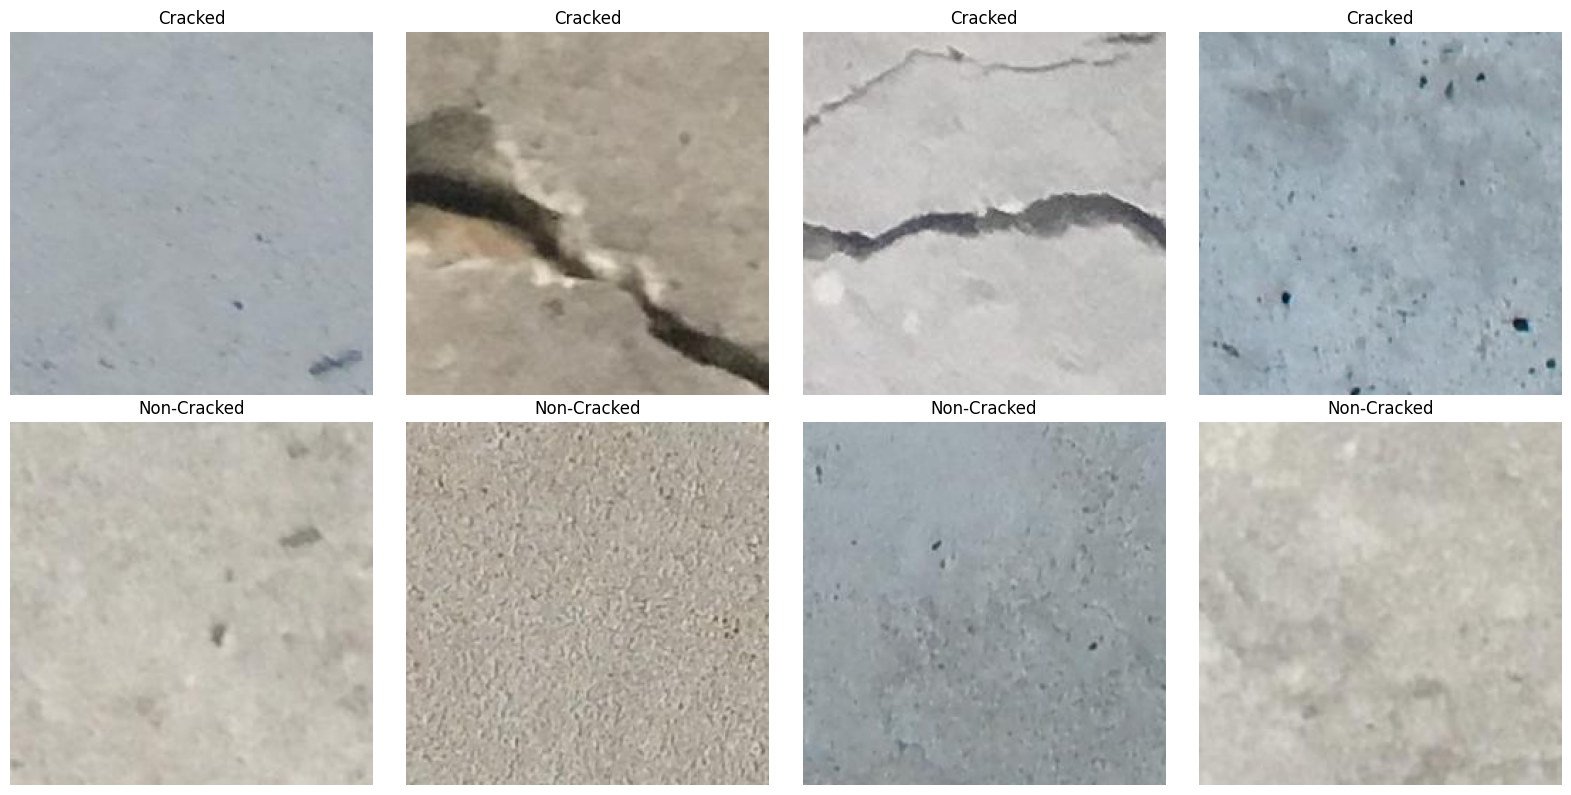

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Locate the two classification folders
cracked_path = os.path.join(
    dataset1_path, "Bangunan Retak", "Cracked"
)

non_cracked_path = os.path.join(
    dataset1_path, "Bangunan Retak", "Non Cracked"
)

# Get image filenames
cracked_images = [
    f for f in os.listdir(cracked_path)
    if f.lower().endswith(image_extensions)
]

non_cracked_images = [
    f for f in os.listdir(non_cracked_path)
    if f.lower().endswith(image_extensions)
]

# Display 4 cracked and 4 non-cracked samples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):

    # Display cracked image
    img = Image.open(
        os.path.join(cracked_path, random.choice(cracked_images))
    ).convert("RGB")

    axes[0, i].imshow(img)
    axes[0, i].set_title("Cracked")
    axes[0, i].axis("off")

    # Display non-cracked image
    img = Image.open(
        os.path.join(non_cracked_path, random.choice(non_cracked_images))
    ).convert("RGB")

    axes[1, i].imshow(img)
    axes[1, i].set_title("Non-Cracked")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [10]:
from PIL import Image
import os
from collections import Counter

# Check image dimensions and formats in both classes
for class_name, folder in [
    ("Cracked", cracked_path),
    ("Non-Cracked", non_cracked_path)
]:

    dimensions = Counter()
    formats = Counter()

    # Inspect up to 1000 images
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ][:1000]

    for filename in files:
        try:
            with Image.open(os.path.join(folder, filename)) as img:
                dimensions[img.size] += 1
                formats[img.format] += 1
        except Exception:
            continue

    print("\nClass:", class_name)
    print("Images inspected:", len(files))
    print("Common dimensions:", dimensions.most_common(5))
    print("Formats:", formats)


Class: Cracked
Images inspected: 1000
Common dimensions: [((227, 227), 704), ((256, 256), 296)]
Formats: Counter({'JPEG': 1000})

Class: Non-Cracked
Images inspected: 1000
Common dimensions: [((256, 256), 714), ((227, 227), 286)]
Formats: Counter({'JPEG': 1000})


In [11]:
import os

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

cracked_count = sum(
    1 for f in os.listdir(cracked_path)
    if f.lower().endswith(image_extensions)
)

non_cracked_count = sum(
    1 for f in os.listdir(non_cracked_path)
    if f.lower().endswith(image_extensions)
)

print("Cracked images:", cracked_count)
print("Non-Cracked images:", non_cracked_count)
print("Total images:", cracked_count + non_cracked_count)


Cracked images: 28484
Non-Cracked images: 67608
Total images: 96092


In [12]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Store image paths and their labels
data = []

# Cracked = 1
for filename in os.listdir(cracked_path):
    if filename.lower().endswith(image_extensions):
        data.append({
            "filepath": os.path.join(cracked_path, filename),
            "label": 1
        })

# Non-Cracked = 0
for filename in os.listdir(non_cracked_path):
    if filename.lower().endswith(image_extensions):
        data.append({
            "filepath": os.path.join(non_cracked_path, filename),
            "label": 0
        })

df = pd.DataFrame(data)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Display split information
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(split)} images")
    print(split["label"].value_counts().rename(index={
        1: "Cracked",
        0: "Non-Cracked"
    }))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))


Training: 67264 images
label
Non-Cracked    47325
Cracked        19939
Name: count, dtype: int64

Validation: 14414 images
label
Non-Cracked    10141
Cracked         4273
Name: count, dtype: int64

Testing: 14414 images
label
Non-Cracked    10142
Cracked         4272
Name: count, dtype: int64

Total: 96092


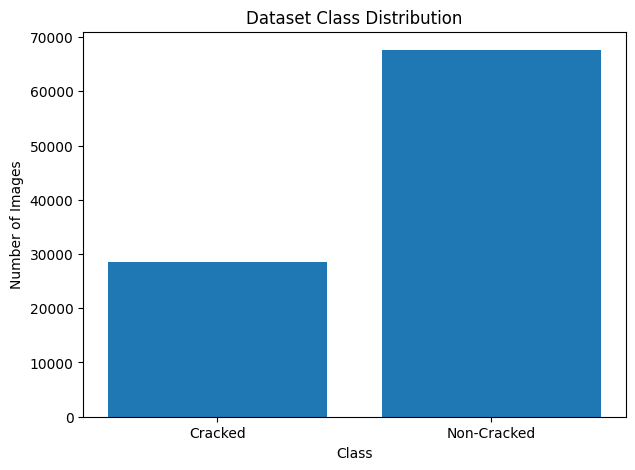

In [13]:
import matplotlib.pyplot as plt

# Count the number of images in each class
class_counts = df["label"].value_counts().sort_index()

# Display class distribution
plt.figure(figsize=(7, 5))
plt.bar(
    ["Cracked", "Non-Cracked"],
    [class_counts[1], class_counts[0]]
)

plt.title("Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [14]:
# Check whether any image paths are duplicated
print("Duplicate paths:", df["filepath"].duplicated().sum())

# Check whether any image paths are missing
print("Missing paths:", (~df["filepath"].apply(os.path.exists)).sum())

Duplicate paths: 0
Missing paths: 0


In [15]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Transformations applied to every image
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),  # Make all images the same size
    transforms.ToTensor(),          # Convert image into a PyTorch tensor
])

# Custom dataset class
class CrackDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get image path and its label
        image_path = self.dataframe.iloc[index]["filepath"]
        label = int(self.dataframe.iloc[index]["label"])

        # Load image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create datasets
train_dataset = CrackDataset(train_df, image_transforms)
val_dataset = CrackDataset(val_df, image_transforms)
test_dataset = CrackDataset(test_df, image_transforms)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 67264
Validation dataset: 14414
Testing dataset: 14414


In [23]:
# Create balanced subsets using the original splits

# Training: 6,000 images per class
train_cracked = train_df[train_df["label"] == 1].sample(
    n=6000, random_state=42
)

train_non_cracked = train_df[train_df["label"] == 0].sample(
    n=6000, random_state=42
)

small_train_df = pd.concat([
    train_cracked, train_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


# Validation: 2,000 images per class
val_cracked = val_df[val_df["label"] == 1].sample(
    n=2000, random_state=42
)

val_non_cracked = val_df[val_df["label"] == 0].sample(
    n=2000, random_state=42
)

small_val_df = pd.concat([
    val_cracked, val_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


# Testing: 2,000 images per class
test_cracked = test_df[test_df["label"] == 1].sample(
    n=2000, random_state=42
)

test_non_cracked = test_df[test_df["label"] == 0].sample(
    n=2000, random_state=42
)

small_test_df = pd.concat([
    test_cracked, test_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


print("Training:", len(small_train_df))
print("Validation:", len(small_val_df))
print("Testing:", len(small_test_df))

Training: 12000
Validation: 4000
Testing: 4000


In [24]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([0, 0, 1, 1, 0, 0, 0, 1, 1, 0])


In [25]:
# Check available hardware
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Using device: cuda
GPU: Tesla T4


In [26]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get labels from the training dataset
train_labels = train_df["label"].values

# Calculate balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_labels
)

# Convert weights into a PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)
print("Class 0: Non-Cracked")
print("Class 1: Cracked")

Class weights: tensor([0.7107, 1.6867], device='cuda:0')
Class 0: Non-Cracked
Class 1: Cracked


In [28]:
import torchvision.models as models
import torch.nn as nn

# --- Load a pretrained MobileNetV2 (lightweight and fast for Colab T4 GPU) ---
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# --- Freeze feature extractor layers so we only train the final classifier ---
for param in model.parameters():
    param.requires_grad = False

# --- Modify the final classifier layer for binary classification (Cracked vs Non-Cracked) ---
# MobileNetV2's classifier is a Sequential block; we replace the final Linear layer.
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 2)
)

# Move model to device (GPU)
model = model.to(device)

print("Pretrained MobileNetV2 loaded and modified successfully!")
print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 150MB/s]

Pretrained MobileNetV2 loaded and modified successfully!
MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(

In [29]:
import torch.nn as nn
import torch.optim as optim

# Loss function for classification
criterion = nn.CrossEntropyLoss()

# Only optimize parameters that require gradients (the new classifier head)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# Optional: Reduce learning rate if validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=1, factor=0.5)

print("Loss function and optimizer initialized!")

Loss function and optimizer initialized!


In [30]:
import time

EPOCHS = 2

for epoch in range(EPOCHS):
    start_time = time.time()

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/2] (244.8s) | Train Loss: 0.2775 | Train Acc: 0.9019 | Val Loss: 0.2132 | Val Acc: 0.9263
Epoch [2/2] (227.0s) | Train Loss: 0.2618 | Train Acc: 0.9064 | Val Loss: 0.2131 | Val Acc: 0.9267


Running evaluation on test set...

              EVALUATION RESULTS
Accuracy  : 93.31%
Precision : 96.62%
Recall    : 80.24%
F1-Score  : 87.67%

Classification Report:
                 precision    recall  f1-score   support

Non-Cracked (0)       0.92      0.99      0.95     10142
    Cracked (1)       0.97      0.80      0.88      4272

       accuracy                           0.93     14414
      macro avg       0.94      0.90      0.92     14414
   weighted avg       0.94      0.93      0.93     14414



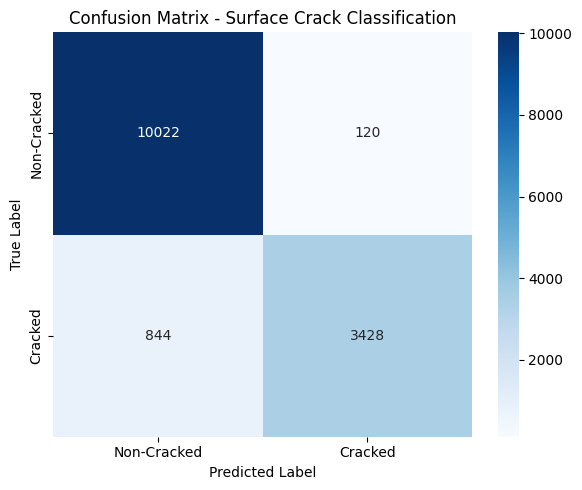


Model state dictionary successfully saved to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth


In [31]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# --- STEP 1: EVALUATE ON TEST DATASET ---
model.eval()
all_preds = []
all_labels = []

print("Running evaluation on test set...")
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# --- STEP 2: CALCULATE METRICS ---
acc = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print("\n" + "="*50)
print("              EVALUATION RESULTS")
print("="*50)
print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")
print("="*50 + "\n")

# Detailed Classification Report
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Non-Cracked (0)", "Cracked (1)"]))

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Cracked", "Cracked"],
            yticklabels=["Non-Cracked", "Cracked"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Surface Crack Classification")
plt.tight_layout()
plt.show()

# --- STEP 3: SAVE THE TRAINED MODEL ---
save_dir = os.path.join(PROJECT_PATH, "models")
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "mobilenet_v2_crack_model.pth")

torch.save(model.state_dict(), save_path)
print(f"\nModel state dictionary successfully saved to: {save_path}")

Model successfully loaded from: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth

Upload an image from your computer to test:


Saving images.jpg to images.jpg


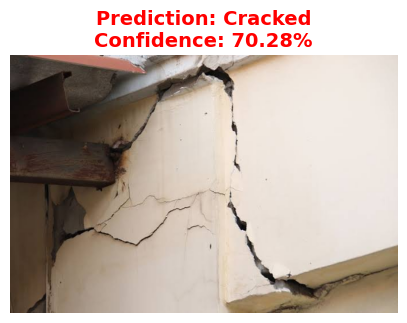

In [32]:
import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import requests
import matplotlib.pyplot as plt
from google.colab import files

# --- STEP 1: DEFINE MODEL ARCHITECTURE & LOAD WEIGHTS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate MobileNetV2 architecture matching your saved checkpoint
model = models.mobilenet_v2(weights=None)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 2)
)

# Load saved weights from Google Drive
model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()
print(f"Model successfully loaded from: {model_path}")

# --- STEP 2: PREPROCESSING TRANSFORMATIONS ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class_names = ["Non-Cracked", "Cracked"]

# --- STEP 3: PREDICTION FUNCTION ---
def predict_image(image_input):
    """
    Accepts a PIL Image, local file path, or image URL and prints the prediction.
    """
    if isinstance(image_input, str):
        if image_input.startswith(('http://', 'https://')):
            # Fetch image from URL
            img = Image.open(requests.get(image_input, stream=True).raw).convert('RGB')
        else:
            # Open local file path
            img = Image.open(image_input).convert('RGB')
    else:
        img = image_input.convert('RGB')

    # Apply preprocessing & add batch dimension
    input_tensor = transform(img).unsqueeze(0).to(device)

    # Perform inference
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        conf, pred_class = torch.max(probabilities, 1)

    predicted_label = class_names[pred_class.item()]
    confidence_pct = conf.item() * 100

    # Display image & prediction result
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_label}\nConfidence: {confidence_pct:.2f}%",
              color="green" if predicted_label == "Non-Cracked" else "red",
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

    return predicted_label, confidence_pct

# --- STEP 4: TEST INFERENCE ---
# Option A: Upload an image file directly from your computer
print("\nUpload an image from your computer to test:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_image(filename)

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
import time

# --- STEP 1: UNFREEZE THE LAST FEW FEATURE BLOCKS ---
# MobileNetV2 features consist of 19 blocks (0 to 18).
# We unfreeze blocks 14 through 18 (the high-level feature extractors).

# First, ensure early layers remain frozen
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 5 blocks of the feature extractor
for layer in model.features[14:]:
    for param in layer.parameters():
        param.requires_grad = True

# Verify which parameters are trainable
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

# --- STEP 2: RE-INITIALIZE OPTIMIZER WITH A VERY SMALL LEARNING RATE ---
# Use a smaller LR (e.g., 1e-4 or 1e-5) to prevent destroying pretrained weights
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)

criterion = nn.CrossEntropyLoss()

# --- STEP 3: FINE-TUNING LOOP (1-2 EPOCHS) ---
FINE_TUNE_EPOCHS = 1

print("\nStarting Fine-Tuning...")
for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Fine-Tune Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# --- STEP 4: SAVE UPDATED FINE-TUNED MODEL ---
fine_tuned_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_finetuned.pth"
torch.save(model.state_dict(), fine_tuned_path)
print(f"\nFine-tuned model saved successfully to: {fine_tuned_path}")

Trainable parameters: 1,683,906 / 2,226,434

Starting Fine-Tuning...
Fine-Tune Epoch [1/1] (241.1s) | Train Loss: 0.1755 | Train Acc: 0.9393 | Val Loss: 0.1489 | Val Acc: 0.9495

Fine-tuned model saved successfully to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_finetuned.pth


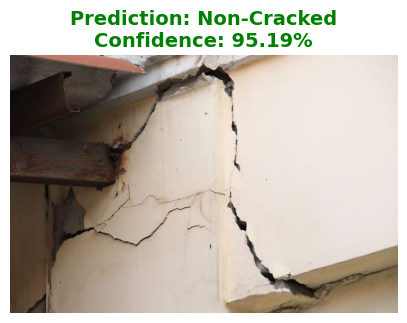

('Non-Cracked', 95.18736004829407)

In [34]:
# Test the same image again
predict_image("images.jpg")

In [35]:
# Re-load the stable, previously saved model weights
model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()
print("Reverted back to the stable feature-extracted model weights!")

Reverted back to the stable feature-extracted model weights!


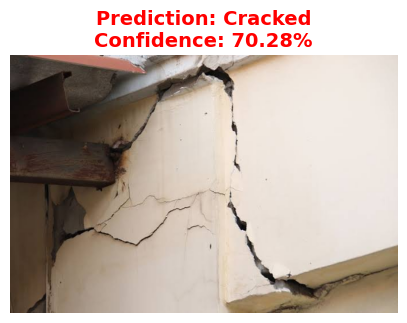

('Cracked', 70.2771544456482)

In [36]:
predict_image("images.jpg")

In [37]:
import torch
import torch.nn as nn
import numpy as np

# Count classes in your training dataframe
class_counts = train_df['label'].value_counts().sort_index().values
print(f"Training Class Distribution - Non-Cracked (0): {class_counts[0]}, Cracked (1): {class_counts[1]}")

# Compute inverse frequency class weights: total_samples / (num_classes * class_count)
total_samples = sum(class_counts)
num_classes = 2
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))

# Convert to torch tensor and move to device
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Calculated Class Weights (Non-Cracked, Cracked): {weights_tensor}")

# Define CrossEntropyLoss with the balanced class weights
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

Training Class Distribution - Non-Cracked (0): 47325, Cracked (1): 19939
Calculated Class Weights (Non-Cracked, Cracked): tensor([0.7107, 1.6867], device='cuda:0')


In [38]:
import torch.optim as optim
import time

# --- UNFREEZE LAST FEW LAYERS ---
for param in model.features.parameters():
    param.requires_grad = False

for layer in model.features[14:]:
    for param in layer.parameters():
        param.requires_grad = True

# --- OPTIMIZER WITH SMALL LEARNING RATE ---
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5  # Very gentle learning rate for fine-tuning
)

FINE_TUNE_EPOCHS = 1

print("\nStarting Weighted Fine-Tuning...")
for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)  # Uses weighted loss here!
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Weighted Fine-Tune Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# Save the newly fine-tuned and balanced model
weighted_model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_balanced_finetuned.pth"
torch.save(model.state_dict(), weighted_model_path)
print(f"\nBalanced fine-tuned model saved to: {weighted_model_path}")


Starting Weighted Fine-Tuning...
Weighted Fine-Tune Epoch [1/1] (242.8s) | Train Loss: 0.2657 | Train Acc: 0.9094 | Val Loss: 0.2031 | Val Acc: 0.9395

Balanced fine-tuned model saved to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_balanced_finetuned.pth


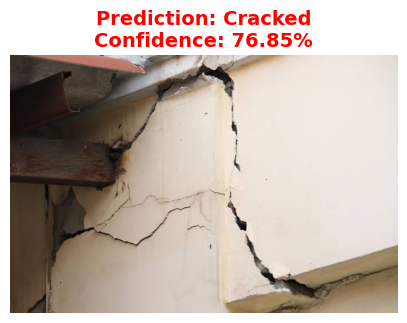

('Cracked', 76.84701681137085)

In [39]:
predict_image("images.jpg")

In [42]:
#USING CNN , WITH DOWNSAMPLED DATASET 1

In [44]:

# Take 5,000 cracked and 5,000 non-cracked images for custom CNN training
cracked_subset = df[df["label"] == 1].sample(n=5000, random_state=42)
non_cracked_subset = df[df["label"] == 0].sample(n=5000, random_state=42)

# Combine and shuffle
custom_train_df = pd.concat([cracked_subset, non_cracked_subset]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Custom Training Dataset Size: {len(custom_train_df)} images")
print(custom_train_df["label"].value_counts().rename(index={1: "Cracked", 0: "Non-Cracked"}))

Custom Training Dataset Size: 10000 images
label
Non-Cracked    5000
Cracked        5000
Name: count, dtype: int64


In [45]:
from torch.utils.data import DataLoader

# Create Dataset instances
custom_train_dataset = CrackDataset(custom_train_df, transform=image_transforms)
val_dataset = CrackDataset(val_df, transform=image_transforms)
test_dataset = CrackDataset(test_df, transform=image_transforms)

# Create DataLoaders (batch size 64 for fast GPU processing)
BATCH_SIZE = 64

custom_train_loader = DataLoader(custom_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Custom DataLoaders created successfully!")

Custom DataLoaders created successfully!


In [46]:
import torch.nn as nn
import torch.nn.functional as F

class CrackCNN(nn.Module):
    def __init__(self):
        super(CrackCNN, self).__init__()
        # Convolutional layers (input images are 224x224x3)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        # After 3 max pooling operations, 224x224 becomes 28x28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2) # Binary classification: [Non-Cracked, Cracked]

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # 224 -> 112
        x = self.pool(F.relu(self.conv2(x))) # 112 -> 56
        x = self.pool(F.relu(self.conv3(x))) # 56 -> 28

        # Flatten for fully connected layers
        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate model, loss function, and optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
custom_model = CrackCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=0.001)

print("Custom CrackCNN initialized on device:", device)
print(custom_model)

Custom CrackCNN initialized on device: cuda
CrackCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)


In [47]:
import time

EPOCHS = 5

print("Starting training of Custom CNN from scratch...")
for epoch in range(EPOCHS):
    start_time = time.time()

    # Training phase
    custom_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in custom_train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = custom_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation phase
    custom_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = custom_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# Save the custom model weights
custom_model_path = os.path.join(PROJECT_PATH, "models", "custom_cnn_crack_model.pth")
torch.save(custom_model.state_dict(), custom_model_path)
print(f"\nCustom CNN model saved successfully to: {custom_model_path}")

Starting training of Custom CNN from scratch...
Epoch [1/5] (75.5s) | Train Loss: 0.5939 | Train Acc: 0.7024 | Val Loss: 0.4265 | Val Acc: 0.8651
Epoch [2/5] (71.6s) | Train Loss: 0.4181 | Train Acc: 0.8229 | Val Loss: 0.3344 | Val Acc: 0.8880
Epoch [3/5] (70.5s) | Train Loss: 0.3887 | Train Acc: 0.8415 | Val Loss: 0.3469 | Val Acc: 0.8864
Epoch [4/5] (71.9s) | Train Loss: 0.3496 | Train Acc: 0.8559 | Val Loss: 0.3476 | Val Acc: 0.8871
Epoch [5/5] (70.5s) | Train Loss: 0.3281 | Train Acc: 0.8607 | Val Loss: 0.3121 | Val Acc: 0.8934

Custom CNN model saved successfully to: /content/drive/MyDrive/Crack_Detection_Project/models/custom_cnn_crack_model.pth


Custom CNN weights loaded successfully!


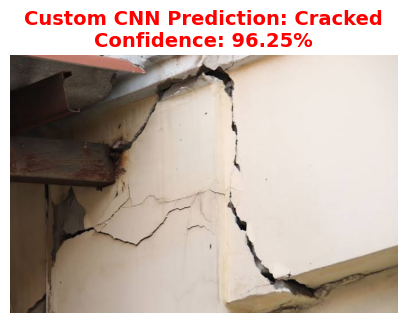

In [48]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# --- STEP 1: LOAD CUSTOM CNN ARCHITECTURE & WEIGHTS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Re-instantiate the same CrackCNN class structure
class CrackCNN(nn.Module):
    def __init__(self):
        super(CrackCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

custom_model = CrackCNN().to(device)
custom_model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/custom_cnn_crack_model.pth"
custom_model.load_state_dict(torch.load(custom_model_path, map_location=device))
custom_model.eval()
print("Custom CNN weights loaded successfully!")

# --- STEP 2: PREDICTION FUNCTION ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])
class_names = ["Non-Cracked", "Cracked"]

def predict_custom_cnn(image_path):
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = custom_model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        conf, pred_class = torch.max(probabilities, 1)

    predicted_label = class_names[pred_class.item()]
    confidence_pct = conf.item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Custom CNN Prediction: {predicted_label}\nConfidence: {confidence_pct:.2f}%",
              color="green" if predicted_label == "Non-Cracked" else "red",
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

# --- STEP 3: TEST ON BUILDING IMAGE ---
predict_custom_cnn("images.jpg")


Or upload another image file from your computer:


Saving new_orleans_nola_fern_plant_tomb_crack_stone-1339337.jpg!d to new_orleans_nola_fern_plant_tomb_crack_stone-1339337.jpg!d


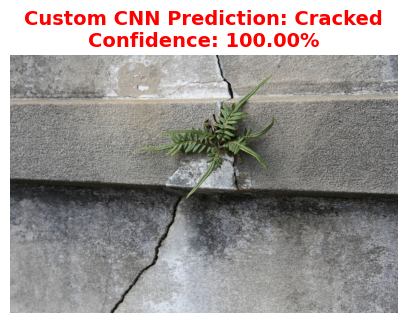

In [49]:
from google.colab import files

print("\nOr upload another image file from your computer:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_custom_cnn(filename)